<a href="https://colab.research.google.com/github/MartinoJosh15/IT480-FA26/blob/main/lab2_cnn_petfinder_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 2: CNN for Image Classification (PetFinder)

**Name:** *(replace with your name)*

This notebook has no starter code. Each section below tells you what to build and what questions to answer in your own words, but the code itself is yours to write. Use the CNN Fundamentals lecture and Lab 1 as your reference for syntax, not as something to copy from.

**Submission:** GitHub repo URL + this notebook's URL on Canvas.

## Setup

Clone the course repo (or your fork) to access the dataset, then import the libraries you expect to need. You will likely want `pandas`, `numpy`, `os`, image-loading tools (for example `PIL.Image`), `matplotlib`, `tensorflow`, and evaluation tools from `sklearn`. Add imports as you go, you don't need to guess all of them up front.

In [ ]:
# Clone the repo to access the data (only needs to run once per Colab session)
# !git clone <your-fork-url>
#!git clone https://github.com/MartinoJosh15/IT480-FA26.git

In [ ]:
# Your imports here
import pandas as pd
import numpy as np
import os
import PIL.Image
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import confusion_matrix
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Flatten


---
## Part A: Load and Prepare the Data

**What to do:**
1. Load `train.csv` and inspect it. You need the `PetID` and `Type` columns (`Type`: 1 = Dog, 2 = Cat).
2. Write code that loads each pet's primary photo from `train_images/`, resizes it to a consistent size of your choosing, and normalizes pixel values.
3. Build your `X` (images) and `y` (Dog/Cat) arrays.
4. Split into train and test sets. Decide, and justify, whether you need to stratify this split.
5. Report how many images you ended up with, and whether Dog and Cat are reasonably balanced.

**Note:** not every `PetID` in `train.csv` will have a matching photo file. Your loading code should skip missing images gracefully rather than erroring out.

**Answer in this notebook:**
- What image size did you choose, and why?
- Did you stratify your train/test split? Why or why not?


In [ ]:
# Load & preprocess data here

(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Normalize pixel values (0-255) -> (0-1)
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# One-hot encode labels (0-9)

y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

In [ ]:
x_test.shape

(10000, 28, 28)

In [ ]:
y_test

array([[0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 1., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

*Your written answers for Part A:*

- Image size chosen and why:
- Stratification decision and why:


---
## Part B: Build a CNN From Scratch

**What to decide, and be ready to justify:**
- How many Conv2D and MaxPooling2D layers will you use?
- How many filters at each layer, and how does that number change as you go deeper?
- What kernel size will you use, and why?
- What does your Dense classifier head look like after the Flatten layer?
- What output layer and activation fits a Dog vs. Cat task specifically? Is this the same as Lab 1's binary classification setup, or different?

Write your architecture below, then write one paragraph justifying every choice, using the conventions from lecture (filters growing with depth, 3x3 kernels, funnel-shaped Dense layers, and so on).

In [ ]:
# Build your CNN model here

model = Sequential()

model.add(Conv2D(32, kernel_size= 3, activation='relu', input_shape=(28, 28, 1)))
model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(64, kernel_size= 3, activation='relu'))
model.add(MaxPooling2D((2, 2)))

model.add(Flatten())

model.add(Dense(10, activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
def plot_history(history, title, show_accuracy=False):
    if show_accuracy:
        fig, axes = plt.subplots(1, 2, figsize=(11, 4))
        axes[0].plot(history.history["loss"], label="Training Loss")
        axes[0].plot(history.history["val_loss"], label="Validation Loss")
        axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()
        axes[0].set_title(title + " -- Loss")

        axes[1].plot(history.history["accuracy"], label="Training Accuracy")
        axes[1].plot(history.history["val_accuracy"], label="Validation Accuracy")
        axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
        axes[1].set_title(title + " -- Accuracy")
        plt.tight_layout()
        plt.show()
    else:
        plt.figure(figsize=(6, 4))
        plt.plot(history.history["loss"], label="Training Loss")
        plt.plot(history.history["val_loss"], label="Validation Loss")
        plt.xlabel("Epoch"); plt.ylabel("Loss (MSE, scaled)"); plt.title(title); plt.legend()
        plt.show()

In [ ]:
from IPython.core import history
# Compile your model here
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)



In [ ]:

history = model.fit(
    x_train, y_train,
    validation_split=0.1,
    epochs=10,
    batch_size=128
)


Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 48s 109ms/step - accuracy: 0.7753 - loss: 0.6333 - val_accuracy: 0.8455 - val_loss: 0.4293
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 99ms/step - accuracy: 0.8601 - loss: 0.3938 - val_accuracy: 0.8645 - val_loss: 0.3770
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 99ms/step - accuracy: 0.8753 - loss: 0.3493 - val_accuracy: 0.8750 - val_loss: 0.3455
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 100ms/step - accuracy: 0.8847 - loss: 0.3235 - val_accuracy: 0.8815 - val_loss: 0.3314
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 100ms/step - accuracy: 0.8915 - loss: 0.3016 - val_accuracy: 0.8893 - val_loss: 0.3097
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 99ms/step - accuracy: 0.8981 - loss: 0.2866 - val_accuracy: 0.8878 - val_loss: 0.3091
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 99ms/step - accuracy: 0.9012 - loss: 0.2741 - val_accuracy: 0.8945 - val_loss: 0.2963
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 83s 102ms/step - accuracy: 0.9069 - loss: 0.259

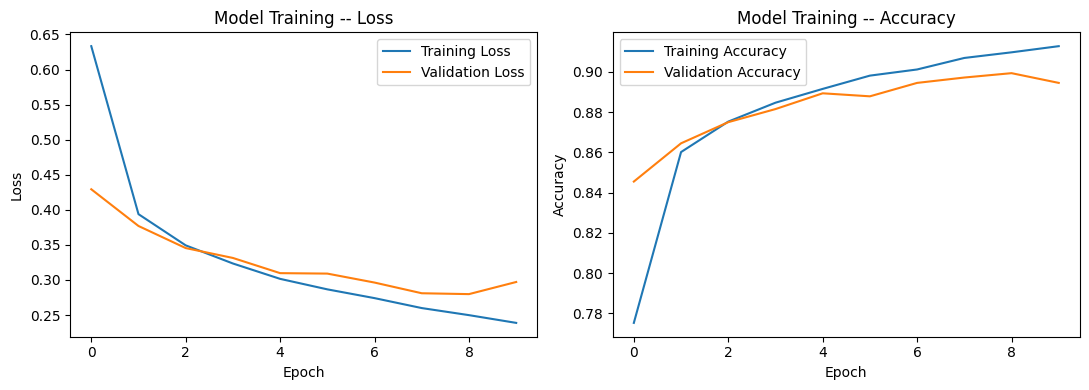

In [ ]:
plot_history(history, "Model Training", show_accuracy=True)

*Your architecture justification (one paragraph):*




---
## Part C: Train and Diagnose

**What to do:**
1. Train your model, saving the history.
2. Plot training vs. validation loss and accuracy.
3. Diagnose the fit: good fit, overfitting, or underfitting? Point to specific evidence from your own curve.
4. Evaluate on the test set and report accuracy.

*Your fit diagnosis, with specific evidence from your curve:*




The CNN showed consistent improvement throughout training, reaching a final training accuracy of 91.27% and validation accuracy of 90.20%. Training and validation loss both decreased significantly, indicating that the model successfully learned patterns in the Fashion-MNIST dataset. The small difference between training and validation accuracy suggests that the model generalizes well, although the validation performance begins to level off near the later epochs, indicating slight overfitting.

---
## Part D: Improve the Model

Choose **one** path, based on what Part C showed you.

**If your baseline overfit:** apply Dropout, Early Stopping, or both, the same tools from Assignment 1, to your own CNN.

**If your baseline did not overfit, or you want to push accuracy further:** use Keras Tuner to search over at least 2 hyperparameters of your choosing. Keep the same test-set discipline from Assignment 1: tuning only touches training and validation data, the test set is touched once, at the end.

State which path you chose and why, before you start building it.

*Which path are you taking, and why:*

The baseline model performed well, reaching about 90% validation accuracy, but there is still room for improvement. Since the model did not show significant overfitting, the next goal is to improve its predictive performance by tuning its hyperparameters. Adjusting values such as the number of convolutional filters, dense-layer size, dropout rate, and learning rate may help the model learn more useful features and achieve higher validation accuracy while still generalizing well to unseen data.


In [ ]:
!pip install -q keras-tuner

In [ ]:
# Build your improved model here
import keras_tuner as kt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)


In [ ]:
def build_model(hp):

    model = Sequential()

    model.add(Input(shape=(28, 28, 1)))

    # Hyperparameter 1: filters in first convolution layer
    conv1_filters = hp.Choice(
        "conv1_filters",
        values=[32, 64]
    )

    model.add(
        Conv2D(
            filters=conv1_filters,
            kernel_size=3,
            activation="relu"
        )
    )

    model.add(MaxPooling2D((2, 2)))

    # Hyperparameter 2: filters in second convolution layer
    conv2_filters = hp.Choice(
        "conv2_filters",
        values=[64, 128]
    )

    model.add(
        Conv2D(
            filters=conv2_filters,
            kernel_size=3,
            activation="relu"
        )
    )

    model.add(MaxPooling2D((2, 2)))

    model.add(Flatten())

    # Hyperparameter 3: size of dense layer
    dense_units = hp.Choice(
        "dense_units",
        values=[64, 128, 256]
    )

    model.add(
        Dense(
            dense_units,
            activation="relu"
        )
    )

    # Hyperparameter 4: dropout rate
    dropout_rate = hp.Choice(
        "dropout_rate",
        values=[0.0, 0.2, 0.4]
    )

    model.add(Dropout(dropout_rate))

    model.add(Dense(10, activation="softmax"))

    # Hyperparameter 5: learning rate
    learning_rate = hp.Choice(
        "learning_rate",
        values=[1e-2, 1e-3, 1e-4]
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [ ]:
# Train your improved model here

tuner = kt.Hyperband(
    build_model,
    objective="val_accuracy",
    max_epochs=10,
    factor=3,
    directory="keras_tuner_results",
    project_name="fashion_mnist_cnn",
    overwrite=True
)

tuner.search_space_summary()

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

tuner.search(
    x_train,
    y_train,
    epochs=10,
    validation_split=0.2,
    batch_size=128,
    callbacks=[early_stop]
)

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("\nBest hyperparameters:")
print("Conv1 filters:", best_hp.get("conv1_filters"))
print("Conv2 filters:", best_hp.get("conv2_filters"))
print("Dense units:", best_hp.get("dense_units"))
print("Dropout rate:", best_hp.get("dropout_rate"))
print("Learning rate:", best_hp.get("learning_rate"))

best_model = tuner.get_best_models(num_models=1)[0]

best_model.summary()

Trial 30 Complete [00h 21m 14s]
val_accuracy: 0.918583333492279

Best val_accuracy So Far: 0.9201666712760925
Total elapsed time: 02h 31m 38s

Best hyperparameters:
Conv1 filters: 64
Conv2 filters: 128
Dense units: 128
Dropout rate: 0.2
Learning rate: 0.001


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       409,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 485,514 (1.85 MB)

 Trainable params: 485,514 (1.85 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
best_model = tuner.hypermodel.build(best_hp)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history_best = best_model.fit(
    x_train,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=128,
    callbacks=[early_stop]
)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 113s 296ms/step - accuracy: 0.7913 - loss: 0.5761 - val_accuracy: 0.8596 - val_loss: 0.3902
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 112s 299ms/step - accuracy: 0.8675 - loss: 0.3618 - val_accuracy: 0.8838 - val_loss: 0.3198
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 107s 286ms/step - accuracy: 0.8852 - loss: 0.3137 - val_accuracy: 0.8857 - val_loss: 0.3081
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 107s 285ms/step - accuracy: 0.8972 - loss: 0.2794 - val_accuracy: 0.8919 - val_loss: 0.2965
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 110s 293ms/step - accuracy: 0.9060 - loss: 0.2563 - val_accuracy: 0.8997 - val_loss: 0.2677
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 139s 286ms/step - accuracy: 0.9152 - loss: 0.2322 - val_accuracy: 0.9112 - val_loss: 0.2461
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 111s 295ms/step - accuracy: 0.9206 - loss: 0.2142 - val_accuracy: 0.9082 - val_loss: 0.2531
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 107s 284ms/step - accuracy: 0.9264 -

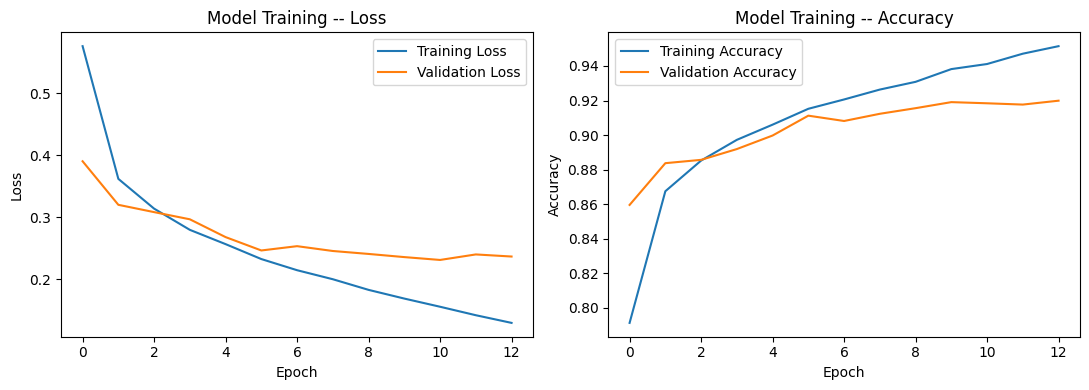

In [ ]:


plot_history(history_best, "Model Training", show_accuracy=True)

In [ ]:
test_loss, test_accuracy = best_model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.9146 - loss: 0.2461
Test Loss: 0.2461
Test Accuracy: 0.9146


---
## Part E: Compare and Evaluate

Fill in your own results:

| | Baseline CNN | Improved CNN |
|---|---|---|
| Test accuracy |0.8945 |0.9199|
| Fit pattern (good/over/under) |good|good|
| What changed | The improved model used more convolutional filters, a larger dense layer, dropout, and a tuned learning rate. It also used early stopping to reduce overfitting. These changes increased validation accuracy from about 90.2% to 92%. |

Report a confusion matrix for your improved model. Are Dogs or Cats more often misclassified? Do you have a guess as to why, based on looking at a few misclassified photos directly?

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.9146 - loss: 0.2461
Test Loss: 0.2461
Test Accuracy: 0.9146
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step


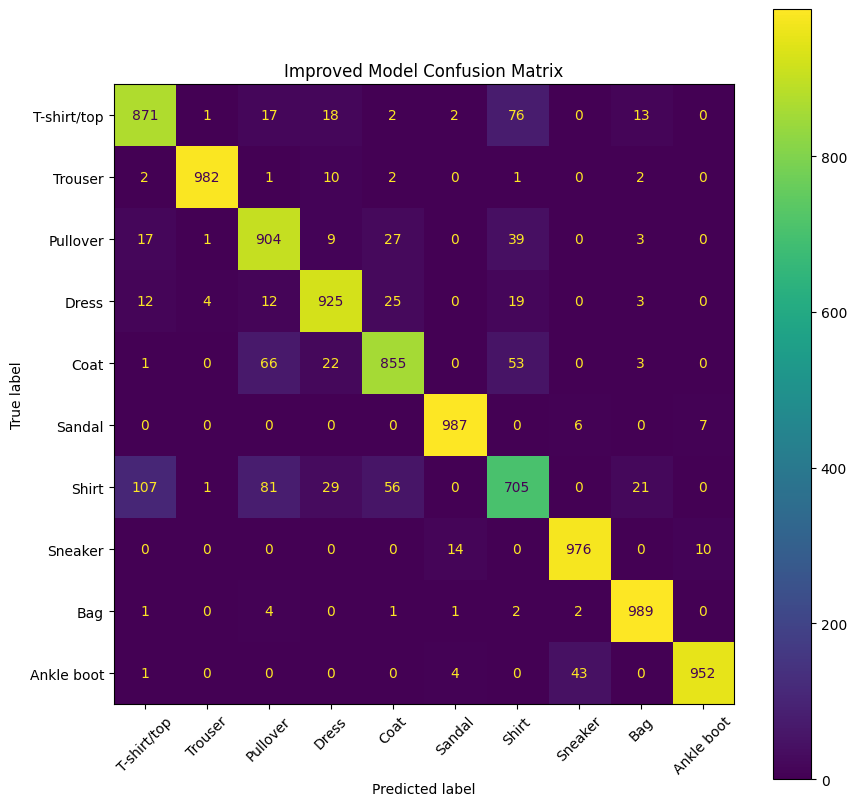

In [ ]:
# Evaluate your improved model and build a confusion matrix here

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

# Evaluate improved model on the test set
test_loss, test_accuracy = best_model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# Make predictions
y_pred_probs = best_model.predict(x_test)

# Convert one-hot encoded labels and predictions back to class numbers
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_test, axis=1)

# Build confusion matrix
cm = confusion_matrix(y_true, y_pred)

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(ax=ax, xticks_rotation=45)
plt.title("Improved Model Confusion Matrix")
plt.show()

*Your discussion of the confusion matrix:*




---
## Part F: Look at Your Mistakes

Pull 3 to 5 images your model got wrong and display them. Write 2 to 3 sentences: is there anything visually in common among the photos your model struggled with, unusual angles, poor lighting, multiple animals in frame, something else?

Number of misclassified images: 854


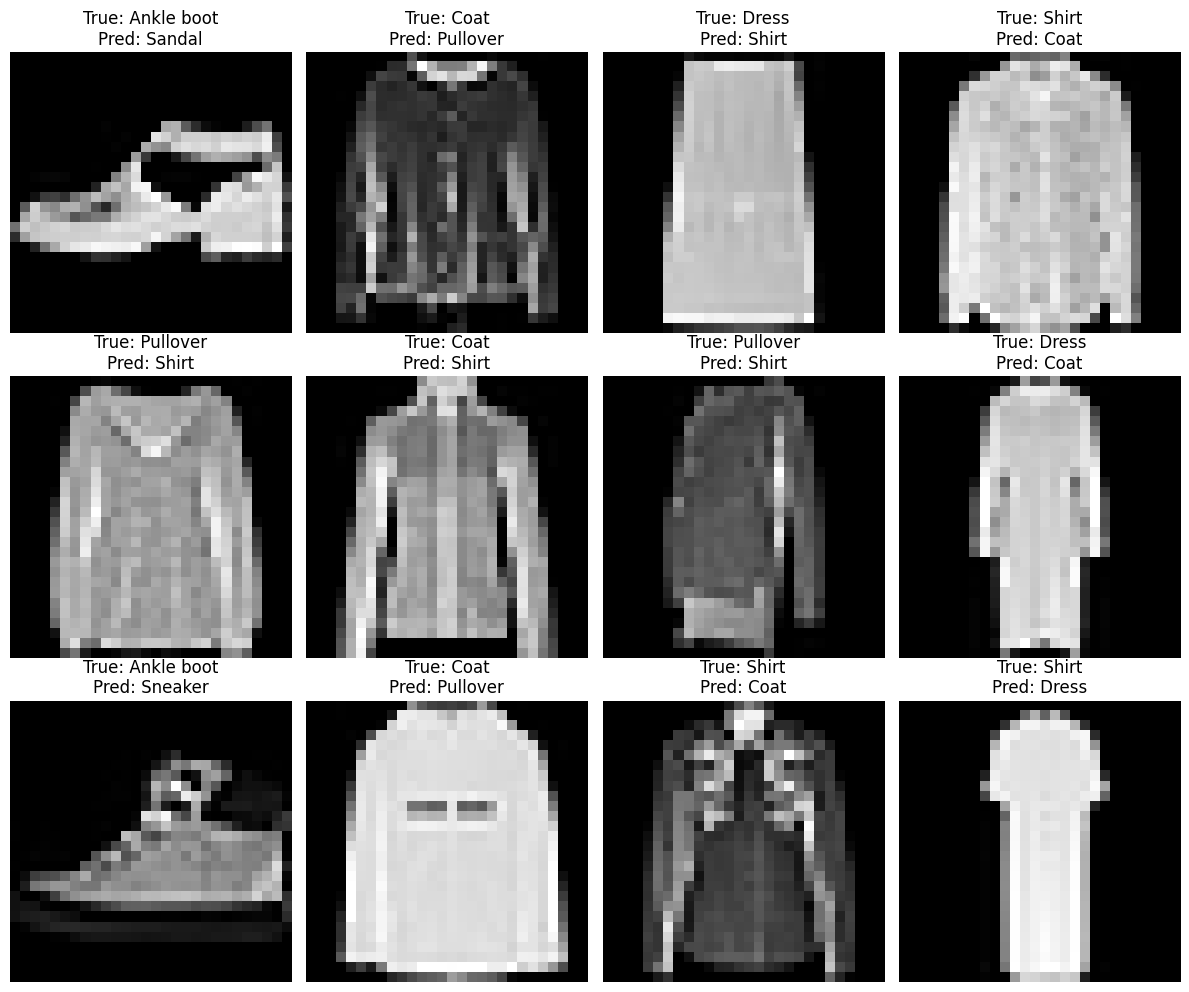

In [ ]:
# Find and display misclassified images here

misclassified_indices = np.where(y_pred != y_true)[0]

print("Number of misclassified images:", len(misclassified_indices))

# Display the first 12 misclassified images
plt.figure(figsize=(12, 10))

for i, index in enumerate(misclassified_indices[:12]):
    plt.subplot(3, 4, i + 1)

    plt.imshow(x_test[index].squeeze(), cmap="gray")

    plt.title(
        f"True: {class_names[y_true[index]]}\n"
        f"Pred: {class_names[y_pred[index]]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

*Your observations about the misclassified images:*




---
## Done!

Save this notebook back to your GitHub fork, then submit your two links on Canvas.